# 03 · Исследование Places API 2ГИС

Ноутбук состоит из трёх частей. Сначала исследуем ответ API на одном центре, затем оцениваем, где разместить центры по городу, и в конце проверяем пагинацию и повторы на искусственных ответах.

**Первые ячейки выполняют реальные запросы и расходуют квоту.** Для запуска сбора с ограничением попыток и сохранением прогресса используй `03_2gis_data_safe.ipynb`. Этот файл служит журналом исследования.


In [1]:
import requests
import os

In [2]:
API_KEY = os.getenv("DGIS_API_KEY")

## Первый запрос

Ищем кофейни в радиусе 1 км от одной точки. `point` задаётся в порядке долгота, широта, `type=branch` ограничивает ответ филиалами, а `page_size` задаёт размер страницы. В ответе нужно смотреть и HTTP-статус, и `meta.code` внутри JSON.

Ключ берётся из окружения. Если ядро его ещё не получило, следующий блок загружает `.env`, но уже созданный словарь `params` сохранит прежнее значение поля `key`. Это ограничение текущего порядка ячеек.


In [3]:
url = "https://catalog.api.2gis.com/3.0/items"

params = {
    "q": "кофейня",
    "point": "76.945,43.238",
    "radius": 1000,
    "type": "branch",
    "page_size": 10,
    "key": API_KEY
}

response = requests.get(url, params=params, timeout=15)
print(response.status_code)


200


In [4]:
from dotenv import load_dotenv
import os

load_dotenv('/Users/david/Desktop/business-location-ai/business-location-ai/.env', override=True)

API_KEY = os.getenv('DGIS_API_KEY')
print("Ключ загружен:", bool(API_KEY))

Ключ загружен: True


In [5]:
response = requests.get(url, params=params, timeout=15)
data = response.json()

print("HTTP:", response.status_code)
print("API code:", data.get("meta", {}).get("code"))
print("Количество организаций:", len(data.get("result", {}).get("items", [])))

HTTP: 200
API code: 200
Количество организаций: 10


### Что возвращает API

Смотрим поля первой организации. По умолчанию в сохранённом примере пришли имя, адрес, тип и ID. Дополнительные поля запрашиваются отдельно. Следующий сетевой вызов добавляет `items.point` и `items.reviews` для геометрии и статистики отзывов.


In [6]:
items = data['result']['items']

print("Количество:", len(items))
print("Поля организации:", items[0].keys())

Количество: 10
Поля организации: dict_keys(['address_name', 'id', 'name', 'type'])


In [7]:
import json

print(json.dumps(items[0], indent=2, ensure_ascii=False))

{
  "address_name": "проспект Абылай хана, 104",
  "id": "70000001104437840",
  "name": "BAL, кофейня",
  "type": "branch"
}


In [8]:
params["fields"] = "items.point,items.reviews"

response = requests.get(url, params=params, timeout=15)
data = response.json()

print("API code:", data["meta"]["code"])

if "result" in data and data["result"].get("items"):
    print(json.dumps(
        data["result"]["items"][0],
        indent=2,
        ensure_ascii=False
    ))

API code: 200
{
  "address_name": "проспект Абылай хана, 104",
  "id": "70000001104437840",
  "name": "BAL, кофейня",
  "point": {
    "lat": 43.246351,
    "lon": 76.942755
  },
  "reviews": {
    "general_rating": 4.9,
    "general_review_count": 2301,
    "general_review_count_with_stars": 5294,
    "is_reviewable": false,
    "is_reviewable_on_flamp": true,
    "items": [
      {
        "is_reviewable": true,
        "tag": "2gis_reviews"
      }
    ],
    "org_rating": 4.7,
    "org_review_count": 7855,
    "org_review_count_with_stars": 16528
  },
  "type": "branch"
}


## Преобразуем ответ в геоданные

Из пары `lon, lat` создаём геометрию Shapely. Исходный слой имеет `EPSG:4326`, затем переводим его в `EPSG:32643` для карты и измерений. Во второй версии таблицы сохраняем также ID, имя, рейтинг и число отзывов.


In [9]:
import geopandas as gpd
from shapely.geometry import Point

items = data['result']['items']

coffee_points = []

for item in items:
    if 'point' in item:
        longitude = item['point']['lon']
        latitude = item['point']['lat']

        coffee_points.append(Point(longitude, latitude))


print(len(coffee_points))


10


In [10]:
coffee_gdf = gpd.GeoDataFrame(
    geometry=coffee_points,
    crs="EPSG:4326"
)



In [11]:
coffee_gdf_m = coffee_gdf.to_crs("EPSG:32643")


coffee_gdf_m.head()

,geometry
0,POINT (657718.565 4790004.611)
1,POINT (657378.892 4788938.449)
2,POINT (658624.682 4789684.598)
3,POINT (657118.299 4789137.312)
4,POINT (658115.917 4789862.515)


In [12]:
import geopandas as gpd
from shapely.geometry import Point

items = data['result']['items']

coffee_records = []

for item in items:
    if 'point' in item:
        longitude = item['point']['lon']
        latitude = item['point']['lat']

        coffee_records.append({
            'id': item['id'],
            'name': item['name'],
            'geometry': Point(longitude, latitude),
            'general_rating' : item["reviews"]["general_rating"],
            'general_review_count' : item["reviews"]["general_review_count"]
        })

print(len(coffee_records))


10


In [13]:
coffee_gdf = gpd.GeoDataFrame(
    coffee_records,
    geometry="geometry",
    crs="EPSG:4326"
).to_crs("EPSG:32643")

coffee_gdf.head()

,id,name,geometry,general_rating,general_review_count
0,70000001104437840,"BAL, кофейня",POINT (657718.565 4790004.611),4.9,2301
1,70000001084456166,"Arabica city cafe, городское кафе",POINT (657378.892 4788938.449),4.8,1143
2,70000001052408859,"Six Coffee+Wine, кофейня",POINT (658624.682 4789684.598),4.9,5646
3,70000001101132415,"Bellocake_kz, кондитерская",POINT (657118.299 4789137.312),4.7,976
4,70000001105830997,"Skyberry, кофейня",POINT (658115.917 4789862.515),4.9,477


In [14]:
print("Количество кофеен:", len(coffee_gdf))
print("Уникальных ID:", coffee_gdf["id"].nunique())
print("Пропущенных координат:", coffee_gdf.geometry.isna().sum())
print("CRS:", coffee_gdf.crs)

Количество кофеен: 10
Уникальных ID: 10
Пропущенных координат: 0
CRS: EPSG:32643


## Сравниваем страницы выдачи

Запрашиваем вторую страницу и сравниваем ID с первой. В сохранённом примере пересечений нет, на двух страницах всего 20 уникальных организаций. Затем отдельным циклом собираем первые пять страниц. Каждый проход этого цикла — отдельный реальный запрос.


In [15]:
params['page'] = 2


response = requests.get(url, params=params, timeout=15)
data_page_2 = response.json()

print("API code:", data_page_2["meta"]["code"])
print("Количество:", len(data_page_2.get("result", {}).get("items", [])))

API code: 200
Количество: 10


In [16]:
ids_page_1 = {item["id"] for item in data["result"]["items"]}
ids_page_2 = {item["id"] for item in data_page_2["result"]["items"]}

print("Общих ID:", len(ids_page_1 & ids_page_2))
print("Всего уникальных:", len(ids_page_1 | ids_page_2))

Общих ID: 0
Всего уникальных: 20


In [17]:
all_items = []

for i in range(1,6):
    params['page'] = i

    response = requests.get(url, params=params, timeout=15)
    data_page = response.json()

    print("Страница:", i)
    print("API code:", data_page["meta"]["code"])


    if data_page['meta']['code'] !=200:
        break

    page_items = data_page.get('result', {}).get('items', [])

    print("Количество:", len(page_items))

    all_items.extend(page_items)

    



Страница: 1
API code: 200
Количество: 10
Страница: 2
API code: 200
Количество: 10
Страница: 3
API code: 200
Количество: 10
Страница: 4
API code: 200
Количество: 10
Страница: 5
API code: 200
Количество: 10


In [18]:
page_items = data_page.get("result", {}).get("items", [])

print("Количество:", len(page_items))
print("Первое заведение:", page_items[0]["name"] if page_items else "Нет данных")
print(len(all_items))

Количество: 10
Первое заведение: Holder coffee, кофейня
50


## Убираем дубликаты и строим карту пилотной выдачи

Сравниваем количество строк и уникальных ID. Словарь с ключом `id` оставляет одну запись на организацию. В сохранённом запуске получено 50 строк и 50 уникальных ID. Для карты берём записи с координатами и перепроецируем их в метры. Геометрия и таблица на этом этапе остаются в памяти ноутбука.


In [19]:
unique_ids = set()

for item in all_items:
    unique_ids.add(item['id'])

print("Уникальных организаций:", len(unique_ids))   

Уникальных организаций: 50


In [20]:
unique_coffees = {}

for item in all_items:
    coffee_id = item['id']

    unique_coffees[coffee_id] = item

print("Всего записей:", len(all_items))
print("Уникальных организаций:", len(unique_coffees))
print("Дубликатов:", len(all_items) - len(unique_coffees))    

Всего записей: 50
Уникальных организаций: 50
Дубликатов: 0


In [21]:
list(unique_coffees.values())[:2]


[{'address_name': 'проспект Абылай хана, 104',
  'id': '70000001104437840',
  'name': 'BAL, кофейня',
  'point': {'lat': 43.246351, 'lon': 76.942755},
  'reviews': {'general_rating': 4.9,
   'general_review_count': 2301,
   'general_review_count_with_stars': 5294,
   'is_reviewable': False,
   'is_reviewable_on_flamp': True,
   'items': [{'is_reviewable': True, 'tag': '2gis_reviews'}],
   'org_rating': 4.7,
   'org_review_count': 7855,
   'org_review_count_with_stars': 16528},
  'type': 'branch'},
 {'address_name': 'улица Наурызбай батыра, 127 блок 1',
  'id': '70000001084456166',
  'name': 'Arabica city cafe, городское кафе',
  'point': {'lat': 43.236827, 'lon': 76.938269},
  'reviews': {'general_rating': 4.8,
   'general_review_count': 1143,
   'general_review_count_with_stars': 2349,
   'is_reviewable': False,
   'is_reviewable_on_flamp': True,
   'items': [{'is_reviewable': True, 'tag': '2gis_reviews'}],
   'org_rating': 4.7,
   'org_review_count': 1143,
   'org_review_count_with_s

In [22]:

unique_coffees_records = []

for item in unique_coffees.values():
    if 'point' in item:
        longitude = item['point']['lon']
        latitude = item['point']['lat']

        reviews = item.get("reviews") or {}

        unique_coffees_records.append({
                    'id': item['id'],
                    'name': item['name'],
                    'geometry': Point(longitude, latitude),
                    "general_rating": reviews.get("general_rating"),
                    "general_review_count": reviews.get("general_review_count")
                })


print(len(unique_coffees_records))


50


In [23]:
unique_coffee_gdf = gpd.GeoDataFrame(
    unique_coffees_records,
    geometry="geometry",
    crs="EPSG:4326"
).to_crs("EPSG:32643")



unique_coffee_gdf.head()

,id,name,geometry,general_rating,general_review_count
0,70000001104437840,"BAL, кофейня",POINT (657718.565 4790004.611),4.9,2301
1,70000001084456166,"Arabica city cafe, городское кафе",POINT (657378.892 4788938.449),4.8,1143
2,70000001052408859,"Six Coffee+Wine, кофейня",POINT (658624.682 4789684.598),4.9,5646
3,70000001101132415,"Bellocake_kz, кондитерская",POINT (657118.299 4789137.312),4.7,976
4,70000001105830997,"Skyberry, кофейня",POINT (658115.917 4789862.515),4.9,477


In [24]:
print("Всего организаций:", len(unique_coffee_gdf))
print("Уникальных ID:", unique_coffee_gdf["id"].nunique())
print("Без рейтинга:", unique_coffee_gdf["general_rating"].isna().sum())
print("CRS:", unique_coffee_gdf.crs)

Всего организаций: 50
Уникальных ID: 50
Без рейтинга: 0
CRS: EPSG:32643


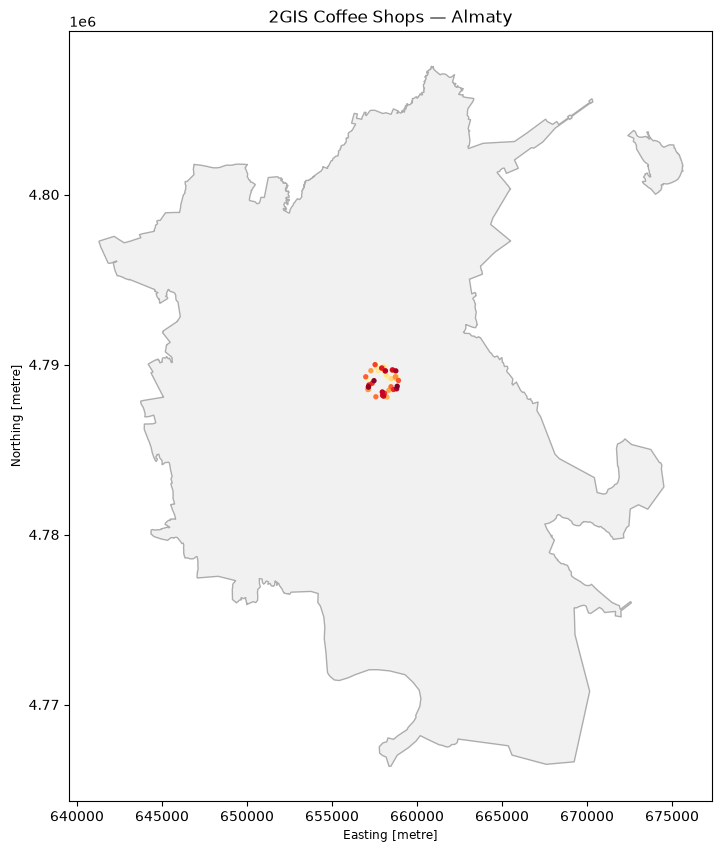

In [25]:
import matplotlib.pyplot as plt

import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt

place = "Almaty, Kazakhstan"

almaty = ox.geocode_to_gdf(place) # получаем географическую границу из территории

fig, ax = plt.subplots(figsize=(12, 10))

metrics_crs = almaty.estimate_utm_crs()
almaty_m = almaty.to_crs(metrics_crs)

almaty_m.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    alpha=0.3
)

unique_coffee_gdf.plot(
    ax=ax,
    cmap="YlOrRd",
    markersize=8,
    legend=True,
    vmin=0,
    vmax=7
)

ax.set_title("2GIS Coffee Shops — Almaty")
plt.show()

In [26]:
data.get("result", {}).get("total")

96

In [27]:
print("Получено записей:", len(all_items))
print("Уникальных ID:", len(unique_coffees))
print("Дубликатов:", len(all_items) - len(unique_coffees))

print(almaty_m.crs)

Получено записей: 50
Уникальных ID: 50
Дубликатов: 0
EPSG:32643


## Строим отдельную сетку центров API

Сетка кандидатов из этапа 02 имеет шаг 500 м. Здесь нужен меньший набор центров запросов, поэтому строим сетку с шагом 1 000 м. Из 1 470 точек прямоугольной сетки 703 находятся внутри границы Алматы. Каждый такой центр может служить началом отдельного радиального поиска.


minX: 641265.5888651052
minY: 4766397.813012956
maxX: 675610.4805611279
maxY: 4807569.400086247
35
42
1470
POINT (641265.5888651052 4766397.813012956)
POINT (641265.5888651052 4767397.813012956)
POINT (641265.5888651052 4768397.813012956)
POINT (641265.5888651052 4769397.813012956)
POINT (641265.5888651052 4770397.813012956)
(1470, 1)
EPSG:32643
703


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

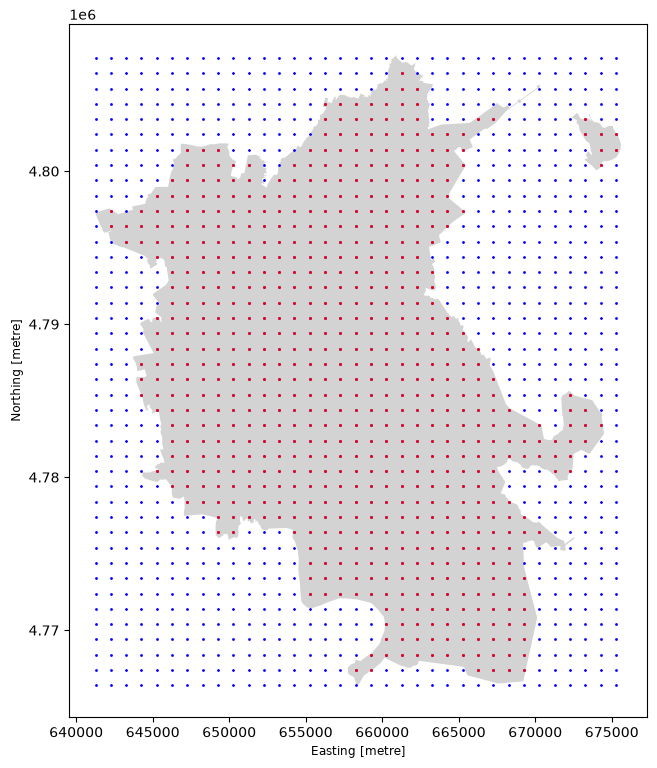

In [28]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from itertools import product


minX, minY, maxX, maxY = almaty_m.total_bounds

print(f'minX: {minX}')
print(f'minY: {minY}')
print(f'maxX: {maxX}')
print(f'maxY: {maxY}')

#создаются границы для создания прямоугольника который покрывает наш полигон
#а точнее карту Алмайти
#minX/minY - sleva, maxX/maxY - sprava

#np.arange() - создает последовательность чисел с определенным шагом

x_coords = np.arange(minX, maxX, 1000)
y_coords = np.arange(minY, maxY, 1000)

coordinates = list(product(x_coords, y_coords))

#Чтобы получить полноценную сетку, нужно составить все комбинации координат X и Y.

print(len(x_coords))
print(len(y_coords))
print(len(coordinates))


# point = Point() # создает точки для каждой пары координат в нашем случае для 5727 пар

all_points_for_almaty = []

for i in range(len(coordinates)):
    
    point = Point(coordinates[i])
    all_points_for_almaty.append(point)


for i in range(5):
    print(all_points_for_almaty[i])



grid = gpd.GeoDataFrame(
    geometry=all_points_for_almaty,
    crs=almaty_m.crs)

print(grid.shape)
print(grid.crs)




#нужно сделать grid Almighty

city_geometry = almaty_m.geometry.union_all()

#происходит векторный цикл который спрашивает ячейка или point внутри алматы или не?
points_inside_city = grid[grid.geometry.within(city_geometry)]

api_grid_gdf = points_inside_city.copy()

print(len(points_inside_city))



fig, ax = plt.subplots(figsize=(9,9))

almaty_m.plot(ax=ax, color='lightgray', markersize=9) # вся карта алматы

grid.plot(ax=ax, color='blue', markersize=1)

points_inside_city.plot(ax=ax, color='red', markersize=1)


In [29]:
print("Всего точек в прямоугольнике:", len(grid))
print("Центров внутри Алматы:", len(api_grid_gdf))

Всего точек в прямоугольнике: 1470
Центров внутри Алматы: 703


### Связываем центры с признаками этапа 02

`sjoin_nearest` переносит признаки ближайшей кандидатной точки на каждый центр. В сохранённом запуске все 703 центра совпали с кандидатами по координатам, и расстояние оказалось нулевым. При другой сетке или иной границе расстояния могут отличаться, а центры с несколькими равноудалёнными соседями могут появиться в таблице несколько раз.


In [30]:
import geopandas as gpd

features_gdf = gpd.read_parquet(
    "../data/processed/almaty_features.parquet"
)

print(features_gdf.shape)
print(features_gdf.crs)

(2822, 14)
{"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 43N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abb

In [31]:
matched = gpd.sjoin_nearest(
    api_grid_gdf,
    features_gdf,
    how="left",
    distance_col="distance_m"
)

print(matched["distance_m"].describe())
print(matched.shape)
print(matched.columns.tolist())

count    703.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: distance_m, dtype: float64
(703, 16)
['geometry', 'index_right', 'cafes_500m', 'cafes_300m', 'cafes_1000m', 'bus_stops_500m', 'residential_buildings_500m', 'houses_500m', 'apartments_500m', 'residential_unknown_500m', 'office_polygons_500m', 'offices_pois_500m', 'universities_500m', 'colleges_500m', 'schools_500m', 'distance_m']


### Первый отбор центров

Оставляем центры, где рядом есть жильё, офисы или университеты. В результате остаётся 367 центров. Это эвристика для расходования квоты, основанная на доступных признаках окружения.


In [32]:
active_api_grid = matched[
    (matched["houses_500m"] > 0) |
    (matched["apartments_500m"] > 0) |
    (matched['office_polygons_500m'] > 0) |
    (matched['offices_pois_500m'] > 0) |
    (matched['universities_500m'] > 0 )
].copy()

In [33]:
print("Было:", len(api_grid_gdf))
print("Стало:", len(active_api_grid))
print("Исключено:", len(api_grid_gdf) - len(active_api_grid))

Было: 703
Стало: 367
Исключено: 336


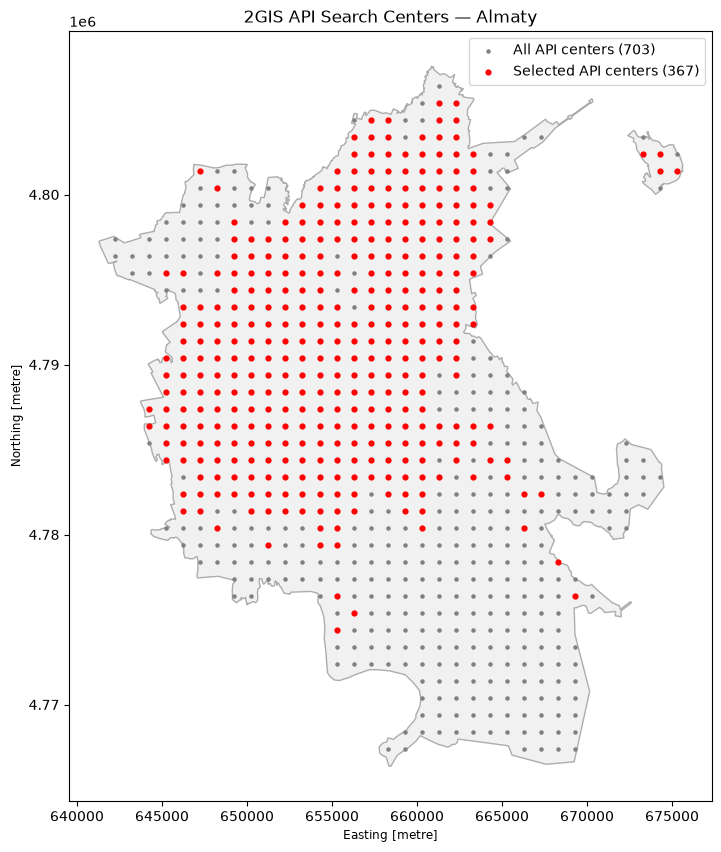

In [34]:
fig, ax = plt.subplots(figsize=(10, 10))

# Границы Алматы
almaty_m.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    alpha=0.3
)

# Все центры поиска
api_grid_gdf.plot(
    ax=ax,
    color="gray",
    markersize=5,
    label="All API centers (703)"
)

# Отобранные центры
active_api_grid.plot(
    ax=ax,
    color="red",
    markersize=12,
    label="Selected API centers (367)"
)

ax.set_title("2GIS API Search Centers — Almaty")
ax.legend()
plt.show()

## Измеряем покрытие двумя способами

Объединяем круги радиуса 1 км. Для площади считаем долю территории города, покрытую объединением. Для кандидатных локаций считаем долю точек, попавших в него. У первого фильтра получилось около 62% площади города и 61,84% кандидатов. Эти показатели описывают геометрию поисковых зон. Полнота ответа API зависит также от поисковой выдачи и доступных страниц.


In [38]:
# Круги вокруг 367 центров
search_buffers = active_api_grid.geometry.buffer(1000)

# Объединяем круги
covered_area = search_buffers.union_all()

# Получаем геометрию всего города
city_geometry = almaty_m.geometry.union_all()


covered_inside_city = covered_area.intersection(city_geometry)

coverage_pct = (
    covered_inside_city.area / city_geometry.area
) * 100


print(f"Coverage: {coverage_pct:.2f}%")

Coverage: 61.98%


In [40]:
#intersection() - тип метры
#intersect() - говорит true/false попало или нет


covered_mask = features_gdf.geometry.intersects(covered_area)

print("Всего локаций:", len(features_gdf))
print("Покрыто:", covered_mask.sum())
print("Не покрыто:", (~covered_mask).sum())

coverage_points_pct = covered_mask.mean() * 100
print(f"Покрытие кандидатных точек: {coverage_points_pct:.2f}%")

Всего локаций: 2822
Покрыто: 1745
Не покрыто: 1077
Покрытие кандидатных точек: 61.84%


### Расширяем фильтр

Проверяем, какие признаки есть у кандидатов за пределами первого покрытия. Добавляем в условие кафе, автобусные остановки, школы и колледжи. Число центров увеличивается с 367 до 413. Круги покрывают ещё 205 кандидатов, всего 1 950 из 2 822 (69,10%). Этот блок рассчитывает сетку и покрытие локально.


In [ ]:
# Анализ непокрытых точек


uncovered_gdf = features_gdf[~covered_mask].copy()


columns = [
    "houses_500m",
    "apartments_500m",
    "office_polygons_500m",
    "offices_pois_500m",
    "universities_500m"
]

#сколько непокрытых точек имеет хотя бы один из наших признаков
print((uncovered_gdf[columns] > 0).any(axis=1).sum())

14


In [42]:
#не пропустили ли мы точки с высокой концентрацией остановок, школ или существующих кофеен.

other_columns = [
    "cafes_500m",
    "bus_stops_500m",
    "schools_500m",
    "colleges_500m"
]

print((uncovered_gdf[other_columns] > 0).any(axis=1).sum())

105


In [44]:
improved_api_grid = matched[
    (matched["houses_500m"] > 0) |
    (matched["apartments_500m"] > 0) |
    (matched["office_polygons_500m"] > 0) |
    (matched["offices_pois_500m"] > 0) |
    (matched["universities_500m"] > 0) |
    (matched["cafes_500m"] > 0) |
    (matched["bus_stops_500m"] > 0) |
    (matched["schools_500m"] > 0) |
    (matched["colleges_500m"] > 0)
].copy()


print("Старый фильтр:", len(active_api_grid))
print("Новый фильтр:", len(improved_api_grid))

Старый фильтр: 367
Новый фильтр: 413


In [45]:
# 1. Создаём круги радиусом 1000 метров
improved_buffers = improved_api_grid.geometry.buffer(1000)

# 2. Объединяем круги
improved_covered_area = improved_buffers.union_all()

# 3. Проверяем кандидатные точки
improved_mask = features_gdf.geometry.intersects(improved_covered_area)

# 4. Рассчитываем покрытие
improved_coverage_pct = improved_mask.mean() * 100

print(f"Старое покрытие: {coverage_points_pct:.2f}%")
print(f"Новое покрытие: {improved_coverage_pct:.2f}%")
print(f"Дополнительно покрыто: {improved_mask.sum() - covered_mask.sum()} точек")

Старое покрытие: 61.84%
Новое покрытие: 69.10%
Дополнительно покрыто: 205 точек


## Прототип пагинации и офлайн-примеры

Первая версия функции запрашивает страницу 1, читает `result.total` и вычисляет число страниц округлением вверх. В тестах `Mock` подменяет `requests.get`. Проверяем три ситуации — несколько страниц, пустую выдачу и HTTP 500. Эти примеры показывают поведение первой версии и не расходуют квоту.


In [47]:
import math

def calculate_pages(total, page_size):
    pages_needed = math.ceil(total / page_size)
    
    return pages_needed


print(calculate_pages(47,10))
print(calculate_pages(100,10))
print(calculate_pages(0,10))

5
10
0


In [48]:

# 1. Получить первую страницу
    # 2. Извлечь total
    # 3. Рассчитать количество страниц
    # 4. Добавить результаты первой страницы
    # 5. Получить оставшиеся страницы
    # 6. Вернуть all_items

'''Разберём:
- requests.get() — отправляет запрос к серверу.
- url — адрес API 2GIS.
- params — параметры поиска: что ищем, где ищем, сколько результатов хотим.
- timeout=15 — не ждать ответа бесконечно, а ограничить ожидание 15 секундами.

data_page = {
    "result": {
        "total": 23,
        "items": [
            {"id": "101", "name": "Coffee A"},
            {"id": "102", "name": "Coffee B"},
            {"id": "103", "name": "Coffee C"}
        ]
    }
}


total = data_page["result"]["total"]
Мы сначала заходим в "result", затем достаём "total". Получаем число 23.

page_items = data_page["result"]["items"]
Получаем список организаций, а не их количество.

'''



def fetch_coffee_shops(url, params):
    all_items = []

    request_params = params.copy()
    request_params["page"] = 1

    response = requests.get(url, params=request_params, timeout=15)
    response.raise_for_status()
    data_page = response.json() 


    total = data_page['result']['total']
    page_size = request_params['page_size']

    pages_needed = calculate_pages(total, page_size)

    page_items = data_page['result']['items']

    all_items.extend(page_items)  # Вот эту


    for page in range(2, pages_needed + 1):
        request_params = params.copy()
        request_params["page"] = page

        response = requests.get(url, params=request_params, timeout=15)
        response.raise_for_status()
        data_page = response.json()

        page_items = data_page['result']['items']

        all_items.extend(page_items)
    
    return all_items

In [49]:
fake_pages = {
    1: {
        "result": {
            "total": 5,
            "items": [
                {"id": "1", "name": "Coffee A"},
                {"id": "2", "name": "Coffee B"}
            ]
        }
    },
    2: {
        "result": {
            "total": 5,
            "items": [
                {"id": "3", "name": "Coffee C"},
                {"id": "4", "name": "Coffee D"}
            ]
        }
    },
    3: {
        "result": {
            "total": 5,
            "items": [
                {"id": "5", "name": "Coffee E"}
            ]
        }
    }
}

In [50]:
from unittest.mock import patch, Mock

def fake_get(url, params, timeout):
    page = params["page"]

    response = Mock()
    response.status_code = 200
    response.json.return_value = fake_pages[page]

    return response


params_test = {
    "page_size": 2
}

with patch("requests.get", side_effect=fake_get) as mocked_get:
    result = fetch_coffee_shops(
        "https://fake-api.test",
        params_test
    )

    print("Организаций:", len(result))
    print("HTTP-запросов:", mocked_get.call_count)
    print("Названия:", [item["name"] for item in result])

Организаций: 5
HTTP-запросов: 3
Названия: ['Coffee A', 'Coffee B', 'Coffee C', 'Coffee D', 'Coffee E']


In [51]:
fake_pages = {
    1: {
        "result": {
            "total": 0,
            "items": []
        }
    }
}

In [52]:
with patch("requests.get", side_effect=fake_get) as mocked_get:
    result = fetch_coffee_shops(
        "https://fake-api.test",
        {"page_size": 10}
    )

    print("Результат:", result)
    print("Количество запросов:", mocked_get.call_count)

Результат: []
Количество запросов: 1


In [53]:
from unittest.mock import patch, Mock
import requests

def fake_get_error(url, params, timeout):
    response = Mock()
    response.status_code = 500

    response.raise_for_status.side_effect = (
        requests.exceptions.HTTPError("500 Server Error")
    )

    return response

with patch("requests.get", side_effect=fake_get_error) as mocked_get:
    try:
        result = fetch_coffee_shops(
            "https://fake-api.test",
            {"page_size": 10}
        )
    except requests.exceptions.HTTPError as e:
        print("Поймали ошибку:", e)

    print("Количество запросов:", mocked_get.call_count)

Поймали ошибку: 500 Server Error
Количество запросов: 1


## Повтор запроса при HTTP-ошибке

Учебный тест имитирует два ответа 500 и успешную третью попытку. Последняя версия пагинации использует этот повтор. У прототипа нет задержки и предела страниц. Когда все попытки исчерпаны, функция возвращает `None`, и её вызывающий код затем пытается прочитать JSON у отсутствующего ответа. Для запуска с реальным ключом предназначен безопасный ноутбук.


In [54]:
def get_with_retry(url, params, max_attempts=3):
    for attempt in range(max_attempts):
        try:
            response = requests.get(
                url,
                params=params,
                timeout=15
            )

            response.raise_for_status()
            return response

        except requests.exceptions.HTTPError:
            print(f"Ошибка на попытке {attempt + 1}")

In [55]:
from unittest.mock import Mock, patch
import requests

def fake_response(status_code):
    response = Mock()
    response.status_code = status_code

    if status_code >= 400:
        response.raise_for_status.side_effect = (
            requests.exceptions.HTTPError(
                f"{status_code} Server Error"
            )
        )

    return response


responses = [
    fake_response(500),
    fake_response(500),
    fake_response(200)
]

with patch("requests.get", side_effect=responses) as mocked_get:
    result = get_with_retry(
        "https://fake-api.test",
        {"page": 2},
        max_attempts=3
    )

    print("Итоговый статус:", result.status_code)
    print("Количество запросов:", mocked_get.call_count)

Ошибка на попытке 1
Ошибка на попытке 2
Итоговый статус: 200
Количество запросов: 3


In [56]:
def fetch_coffee_shops(url, params):
    all_items = []

    # Получаем первую страницу
    request_params = params.copy()
    request_params["page"] = 1

    response = get_with_retry(url, request_params)
    data_page = response.json()

    # Вычисляем количество страниц
    total = data_page["result"]["total"]
    page_size = request_params["page_size"]
    pages_needed = calculate_pages(total, page_size)

    # Сохраняем организации первой страницы
    page_items = data_page["result"]["items"]
    all_items.extend(page_items)

    # Получаем остальные страницы
    for page in range(2, pages_needed + 1):
        request_params["page"] = page

        response = get_with_retry(url, request_params)
        data_page = response.json()

        page_items = data_page["result"]["items"]
        all_items.extend(page_items)

    return all_items